# 01 — Data Analysis

## Project overview
Initial exploration of the resume and job-matching dataset: structure, missing values, duplicated fields, reference score, and job-position distribution.

**Output:** a clear understanding of the raw data before preprocessing.

In [22]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [23]:
df = pd.read_csv(r"D:\Instant AI\AI\Graduation Project\My Project\Data\resume_data_for_ranking.csv")

## 1. First look at the dataset
We inspect the first records, dimensions, columns, and data types.

In [24]:
df.head()

,address,career_objective,skills,educational_institution_name,degree_names,passing_years,educational_results,result_types,major_field_of_studies,professional_company_names,...,online_links,issue_dates,expiry_dates,job_position_name,educationaL_requirements,experiencere_requirement,age_requirement,responsibilities.1,skills_required,matched_score
0,NaN,Big data analytics working and database wareho...,"['Big Data', 'Hadoop', 'Hive', 'Python', 'Mapr...",['The Amity School of Engineering & Technology...,['B.Tech'],['2019'],['N/A'],[None],['Electronics'],['Coca-COla'],...,NaN,NaN,NaN,Senior Software Engineer,B.Sc in Computer Science & Engineering from a ...,At least 1 year,NaN,Technical Support\nTroubleshooting\nCollaborat...,NaN,0.850000
1,NaN,Fresher looking to join as a data analyst and ...,"['Data Analysis', 'Data Analytics', 'Business ...","['Delhi University - Hansraj College', 'Delhi ...","['B.Sc (Maths)', 'M.Sc (Science) (Statistics)']","['2015', '2018']","['N/A', 'N/A']","['N/A', 'N/A']","['Mathematics', 'Statistics']",['BIB Consultancy'],...,NaN,NaN,NaN,Machine Learning (ML) Engineer,M.Sc in Computer Science & Engineering or in a...,At least 5 year(s),NaN,Machine Learning Leadership\nCross-Functional ...,NaN,0.750000
2,NaN,NaN,"['Software Development', 'Machine Learning', '...","['Birla Institute of Technology (BIT), Ranchi']",['B.Tech'],['2018'],['N/A'],['N/A'],['Electronics/Telecommunication'],['Axis Bank Limited'],...,NaN,NaN,NaN,"Executive/ Senior Executive- Trade Marketing, ...",Master of Business Administration (MBA),At least 3 years,NaN,"Trade Marketing Executive\nBrand Visibility, S...",Brand Promotion\nCampaign Management\nField Su...,0.416667
3,NaN,To obtain a position in a fast-paced business ...,"['accounts payables', 'accounts receivables', ...","['Martinez Adult Education, Business Training ...",['Computer Applications Specialist Certificate...,['2008'],[None],[None],['Computer Applications'],"['Company Name ï¼ City , State', 'Company Name...",...,NaN,NaN,NaN,Business Development Executive,Bachelor/Honors,1 to 3 years,Age 22 to 30 years,Apparel Sourcing\nQuality Garment Sourcing\nRe...,Fast typing skill\nIELTSInternet browsing & on...,0.760000
4,NaN,Professional accountant with an outstanding wo...,"['Analytical reasoning', 'Compliance testing k...",['Kent State University'],['Bachelor of Business Administration'],[None],['3.84'],[None],['Accounting'],"['Company Name', 'Company Name', 'Company Name...",...,[None],[None],"['February 15, 2021']",Senior iOS Engineer,Bachelor of Science (BSc) in Computer Science,At least 4 years,NaN,iOS Lifecycle\nRequirement Analysis\nNative Fr...,iOS\niOS App Developer\niOS Application Develo...,0.650000


In [25]:
df.shape

(9544, 35)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9544 entries, 0 to 9543
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   address                              784 non-null    str    
 1   career_objective                     4740 non-null   str    
 2   skills                               9488 non-null   str    
 3   educational_institution_name         9460 non-null   str    
 4   degree_names                         9460 non-null   str    
 5   passing_years                        9460 non-null   str    
 6   educational_results                  9460 non-null   str    
 7   result_types                         9460 non-null   str    
 8   major_field_of_studies               9460 non-null   str    
 9   professional_company_names           9460 non-null   str    
 10  company_urls                         9460 non-null   str    
 11  start_dates                          9460

## 2. Missing values and data quality
Missing-value counts are reviewed before cleaning.

In [27]:
df.isnull().sum()

address                                8760
career_objective                       4804
skills                                   56
educational_institution_name             84
degree_names                             84
passing_years                            84
educational_results                      84
result_types                             84
major_field_of_studies                   84
professional_company_names               84
company_urls                             84
start_dates                              84
end_dates                                84
related_skils_in_job                     84
positions                                84
locations                                84
responsibilities                          0
extra_curricular_activity_types        6118
extra_curricular_organization_names    6118
extra_curricular_organization_links    6118
role_positions                         6118
languages                              8844
proficiency_levels              

In [28]:
df.duplicated().sum()

np.int64(0)

## 3. Initial cleaning decisions
Non-essential or duplicated fields are removed while useful profile and job information is retained.

## 4. Checking duplicated information
The duplicated `responsibilities` fields are compared before one copy is removed.

In [29]:
df['experiencere_requirement'].isna()

0       False
1       False
2       False
3       False
4       False
        ...  
9539    False
9540    False
9541    False
9542    False
9543    False
Name: experiencere_requirement, Length: 9544, dtype: bool

In [30]:
df[['responsibilities', 'responsibilities.1']].head(10)

,responsibilities,responsibilities.1
0,Technical Support\nTroubleshooting\nCollaborat...,Technical Support\nTroubleshooting\nCollaborat...
1,Machine Learning Leadership\nCross-Functional ...,Machine Learning Leadership\nCross-Functional ...
2,"Trade Marketing Executive\nBrand Visibility, S...","Trade Marketing Executive\nBrand Visibility, S..."
3,Apparel Sourcing\nQuality Garment Sourcing\nRe...,Apparel Sourcing\nQuality Garment Sourcing\nRe...
4,iOS Lifecycle\nRequirement Analysis\nNative Fr...,iOS Lifecycle\nRequirement Analysis\nNative Fr...
5,Machine Learning Design\nData Analysis\nModel ...,Machine Learning Design\nData Analysis\nModel ...
6,iOS Lifecycle\nRequirement Analysis\nNative Fr...,iOS Lifecycle\nRequirement Analysis\nNative Fr...
7,iOS Lifecycle\nRequirement Analysis\nNative Fr...,iOS Lifecycle\nRequirement Analysis\nNative Fr...
8,Machinery Maintenance\nTroubleshooting\nReport...,Machinery Maintenance\nTroubleshooting\nReport...
9,Apparel Sourcing\nQuality Garment Sourcing\nRe...,Apparel Sourcing\nQuality Garment Sourcing\nRe...


In [31]:
(df['responsibilities'] == df['responsibilities.1']).mean()

np.float64(1.0)

## 5. Dataset structure and target analysis
We inspect data types, requirements, the existing `matched_score`, unique values, and duplicate records. `matched_score` is the dataset-provided reference value used later for evaluation.

In [32]:
df.dtypes

address                                    str
career_objective                           str
skills                                     str
educational_institution_name               str
degree_names                               str
passing_years                              str
educational_results                        str
result_types                               str
major_field_of_studies                     str
professional_company_names                 str
company_urls                               str
start_dates                                str
end_dates                                  str
related_skils_in_job                       str
positions                                  str
locations                                  str
responsibilities                           str
extra_curricular_activity_types            str
extra_curricular_organization_names        str
extra_curricular_organization_links        str
role_positions                             str
languages    

In [33]:
df[['experiencere_requirement', 'age_requirement', 'matched_score']].head(20)

,experiencere_requirement,age_requirement,matched_score
0,At least 1 year,NaN,0.850000
1,At least 5 year(s),NaN,0.750000
2,At least 3 years,NaN,0.416667
3,1 to 3 years,Age 22 to 30 years,0.760000
4,At least 4 years,NaN,0.650000
5,NaN,NaN,0.850000
6,At least 4 years,NaN,0.650000
7,At least 4 years,NaN,0.650000
8,2 to 5 years,Age 25 to 40 years,0.550000
9,1 to 3 years,Age 22 to 30 years,0.383333


In [34]:
df['matched_score'].describe()

count    9544.000000
mean        0.660831
std         0.167040
min         0.000000
25%         0.583333
50%         0.683333
75%         0.793333
max         0.970000
Name: matched_score, dtype: float64

In [35]:
df.nunique().sort_values()

online_links                             7
extra_curricular_organization_links      9
expiry_dates                            11
age_requirement                         14
company_urls                            16
experiencere_requirement                17
languages                               18
educationaL_requirements                20
proficiency_levels                      22
skills_required                         23
job_position_name                       28
address                                 28
responsibilities.1                      28
responsibilities                        28
result_types                            30
issue_dates                             30
certification_skills                    32
certification_providers                 49
educational_results                     78
extra_curricular_activity_types         86
locations                               86
extra_curricular_organization_names     89
role_positions                          91
passing_yea

In [36]:
df.isnull().sum()

address                                8760
career_objective                       4804
skills                                   56
educational_institution_name             84
degree_names                             84
passing_years                            84
educational_results                      84
result_types                             84
major_field_of_studies                   84
professional_company_names               84
company_urls                             84
start_dates                              84
end_dates                                84
related_skils_in_job                     84
positions                                84
locations                                84
responsibilities                          0
extra_curricular_activity_types        6118
extra_curricular_organization_names    6118
extra_curricular_organization_links    6118
role_positions                         6118
languages                              8844
proficiency_levels              

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.duplicated(keep=False).sum()

np.int64(0)

## 6. Job-position distribution
We examine the number and frequency of job positions represented in the dataset.

In [39]:
df['job_position_name'].nunique()

28

In [40]:
df['job_position_name'].value_counts()

job_position_name
Project Coordinator (Civil)                                                                342
HR Officer                                                                                 342
Civil Engineer                                                                             342
Site Engineer                                                                              342
Senior Software Engineer                                                                   341
Executive/ Senior Executive- Trade Marketing, Hygiene Products                             341
Business Development Executive                                                             341
AI Engineer                                                                                341
Mechanical Engineer                                                                        341
Mechanical Designer                                                                        341
Asst. Manager/ Manger (Administr

## 7. Visual exploration
The score distribution and average score by job position provide an initial visual understanding of the data.

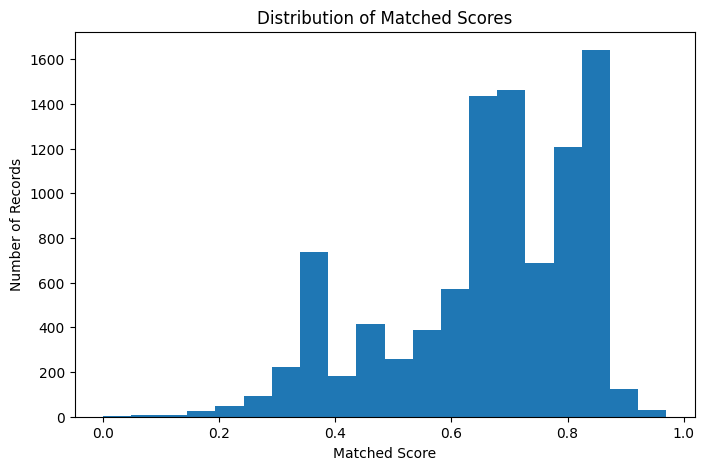

In [41]:
plt.figure(figsize=(8,5))

plt.hist(df['matched_score'], bins=20)

plt.xlabel('Matched Score')
plt.ylabel('Number of Records')
plt.title('Distribution of Matched Scores')

plt.show()

## Conclusion
The raw dataset has been explored and basic quality issues identified. Notebook 02 prepares consistent text fields for NLP and machine learning.

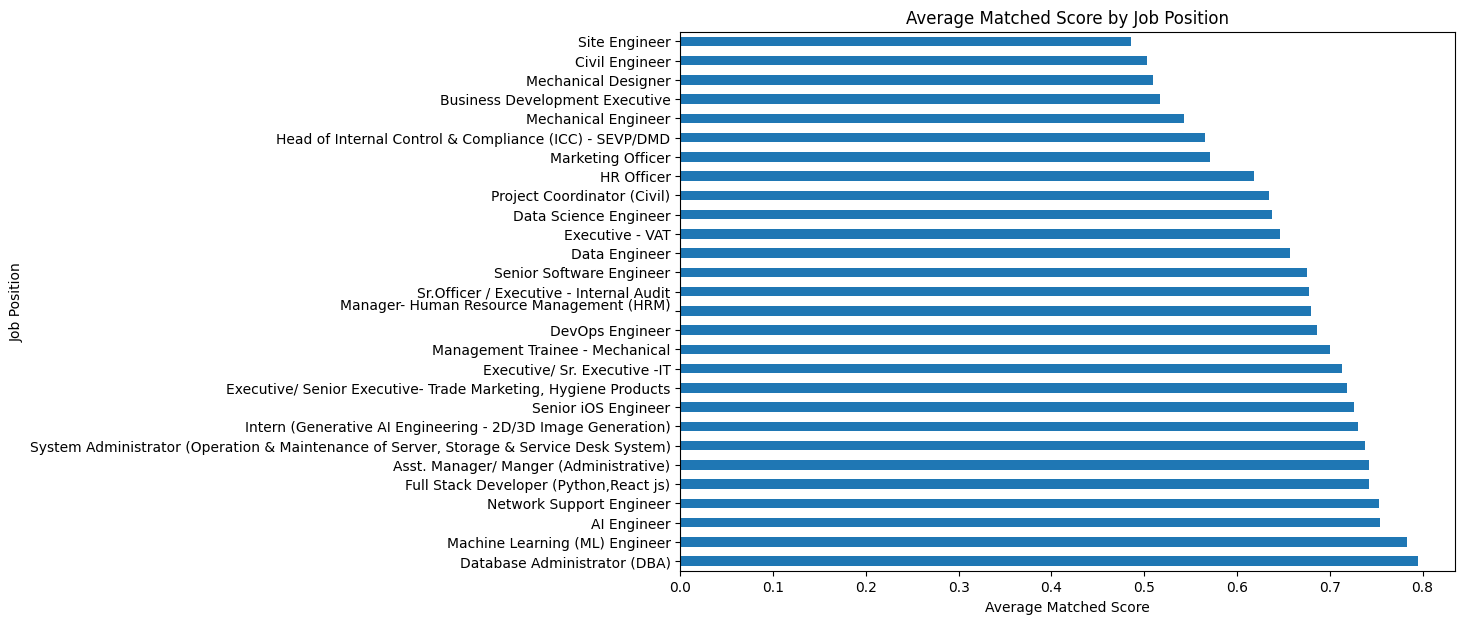

In [42]:
job_score = (
    df.groupby('job_position_name')['matched_score']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 7))

job_score.plot(kind='barh')

plt.xlabel('Average Matched Score')
plt.ylabel('Job Position')
plt.title('Average Matched Score by Job Position')

plt.show()